# One school campus, building by building: University High School, Parkville

What does one shape per school hide? One school drawn as its buildings, rolled up to the site, with estimated floor
space per student.

The other school showcases draw one shape per school and divide its grounds (the land it sits on, buildings included)
by its students. That is a site-level figure. This notebook takes one campus and reports it building by building, then
rolls the buildings back up to the site, so the two can be compared. Students are February FTE enrolments (Victorian
Department of Education), not a headcount.

The shapes in `data/geometry/` were made in [Plotlay](https://www.getplotlay.com): the site from the City of Melbourne's
two property parcels (University High School and the Elizabeth Blackburn School of Sciences), and each building picked
from the council's 2023 building footprints, the parts of one structure joined by `structure_id`. The site's roll-up
(how many buildings, their footprint and floor area) was worked out in Plotlay from the buildings that stand inside it.

It reads only the files in `../data`. Enrolments are the school's: they are divided at site level only, never split
across buildings. Floor space is an estimate from the council's heights, said wherever it is used.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='.*colormapping.*')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA = '../data'
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
INK, MUTED = '#1d4f91', '#5b6573'
ERA = {'1930, built (CLUE)': '#E69F00', '2014, built (CLUE)': '#56B4E9', 'On the 2014 outlines': '#009E73', 'Shown from the 2018 footprints': '#F0E442', 'Shown from the 2023 footprints': '#0072B2'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## Sources and licence

Building outlines 2014 and 2015, building footprints 2018, 2020 and 2023, property boundaries and the Census of Land Use
and Employment (CLUE) building information: City of Melbourne Open Data, CC BY 4.0. February FTE enrolments: Victorian
Department of Education, All Schools FTE Enrolments (DataVic), CC BY 4.0. Nothing comes from OpenStreetMap or aerial
imagery. Full credits are in `NOTICE`. `data/sample/` is sample data (invented) and is used only in the last section, labelled so.

## Load

In [2]:
b = pd.read_csv(f'{DATA}/buildings/buildings.csv', dtype={'structure_id': str})
fy = pd.read_csv(f'{DATA}/buildings/footprint_by_year.csv')
enr = pd.read_csv(f'{DATA}/site/enrolments.csv')
clue = pd.read_csv(f'{DATA}/site/clue_records.csv')
roll = pd.read_csv(f'{DATA}/site/site_rollup.csv')
shapes = gpd.read_file(f'{DATA}/geometry/campus_buildings.geojson').to_crs(7855)
site = gpd.read_file(f'{DATA}/geometry/campus_site.geojson').to_crs(7855)
assert b.key.is_unique and set(b.key) == set(shapes.key)
print(len(b), 'buildings;', len(site), 'site shape in', int(roll.parts[0]), 'parts;', enr.year.min(), 'to', enr.year.max(), 'enrolments')
b[['key', 'structure_id', 'footprint_m2', 'height_m', 'roof', 'first_mapped', 'era', 'storeys_est', 'storeys_from', 'floor_m2_est', 'clue_construction_year', 'clue_floors', 'clue_accessibility_rating']]

13 buildings; 1 site shape in 2 parts; 2007 to 2026 enrolments


,key,structure_id,footprint_m2,height_m,roof,first_mapped,era,storeys_est,storeys_from,floor_m2_est,clue_construction_year,clue_floors,clue_accessibility_rating
0,B01,811846,6433.7,18.0,Flat/Hip,2014,"1930, built (CLUE)",3,CLUE floors (cap),17939,1930.0,3.0,2.0
1,B02,811844,883.3,13.5,Flat/Gable/Hip,2014,On the 2014 outlines,3,height,1960,NaN,NaN,NaN
2,B03,811043,835.8,18.0,Flat,2015,"2014, built (CLUE)",3,CLUE floors (cap),2386,2014.0,3.0,3.0
3,B04,900635,204.6,4.0,Gable,2023,Shown from the 2023 footprints,1,height,205,NaN,NaN,NaN
4,B05,900636,202.0,3.8,Gable,2023,Shown from the 2023 footprints,1,height,203,NaN,NaN,NaN
5,B06,901093,198.5,3.7,Gable,2023,Shown from the 2023 footprints,1,height,199,NaN,NaN,NaN
6,B07,900641,197.8,3.7,Gable,2023,Shown from the 2023 footprints,1,height,199,NaN,NaN,NaN
7,B08,900645,197.4,3.8,Gable,2023,Shown from the 2023 footprints,1,height,198,NaN,NaN,NaN
8,B09,900644,194.8,3.9,Gable,2023,Shown from the 2023 footprints,1,height,195,NaN,NaN,NaN
9,B10,811842,71.8,3.0,Flat,2014,On the 2014 outlines,1,height,72,NaN,NaN,NaN


## The site as one shape

What a one-shape-per-school map knows: the site's area and the school's enrolment.

In [3]:
site_m2 = site.geometry.area.sum()
fte = enr.set_index('year').fte_students
print(f'Site: {site_m2:,.0f} m² (Plotlay worked out {roll.area_m2[0]:,.0f} m²)')
for y in (fte.index.min(), 2025):
    print(f'{y}: {fte[y]:,.1f} students, {site_m2 / fte[y]:.1f} m² of grounds each')
print(f'Enrolment {fte.index.min()} to {fte.index.max()}: {fte.iloc[-1] / fte.iloc[0] - 1:+.0%}')

Site: 24,233 m² (Plotlay worked out 24,233 m²)
2007: 1,209.6 students, 20.0 m² of grounds each
2025: 1,983.4 students, 12.2 m² of grounds each
Enrolment 2007 to 2026: +65%


The council's land use census (CLUE) has one record for the school's property in every census year, and one for the
science school since it opened. It describes a building, not the campus:

In [4]:
clue.groupby('clue_property_id').agg(first=('census_year', 'min'), last=('census_year', 'max'), years=('census_year', 'nunique'), name=('building_name', 'last'), built=('construction_year', 'last'), floors=('floors', 'last'), access=('accessibility_rating', 'last'))

,first,last,years,name,built,floors,access
clue_property_id,,,,,,,
109209,2002,2024,23,University High School,1930,3,2.0
674741,2016,2024,9,Building 405 Elizabeth Blackburn,2014,3,3.0


## Building by building

The council's 2023 footprints show the buildings on the site. `height_m` is the top of a building's highest part above
the lowest base of the structure, as the council measures it (on a sloping site the uphill side reads a little taller).
Storeys and floor area are estimated: height divided by 4 m floor to floor, 2 m taken off a pitched roof, never more than
the CLUE floors where the census has a record for that building.

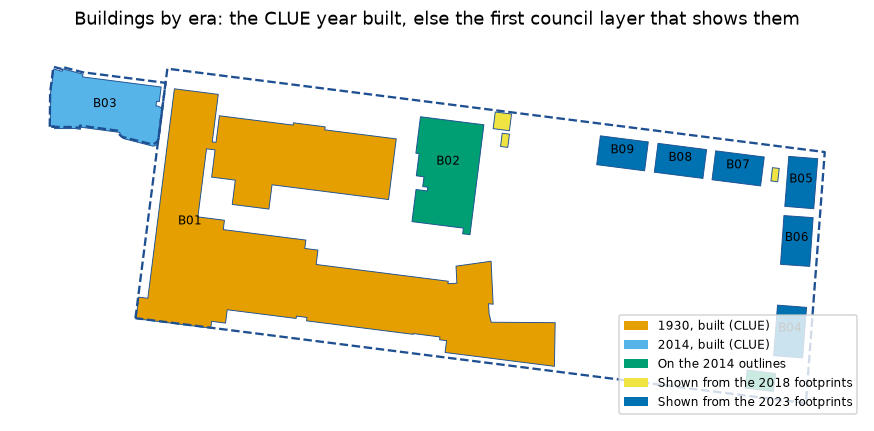

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
site.boundary.plot(ax=ax, color=INK, lw=1.5, ls='--')
sh = shapes.merge(b[['key', 'era']], on='key')
for era, g in sh.groupby('era'): g.plot(ax=ax, color=ERA[era], edgecolor=INK, lw=.6, label=era)
for _, r in sh.iterrows():
    if r.geometry.area > 150: ax.annotate(r.key, r.geometry.representative_point().coords[0], ha='center', fontsize=8)
ax.set_axis_off(); ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=ERA[e]) for e in ERA if e in set(sh.era)], labels=[e for e in ERA if e in set(sh.era)], fontsize=8, loc='lower right')
ax.set_title('Buildings by era: the CLUE year built, else the first council layer that shows them'); plt.show()

In [6]:
fp_total, floor_total = b.footprint_m2.sum(), b.floor_m2_est.sum()
assert abs(fp_total - roll.footprint_m2[0]) < 2 and abs(floor_total - roll.floor_m2_est[0]) < 1   # Plotlay's roll-up
print(f'{len(b)} buildings: footprint {fp_total:,.0f} m² ({fp_total / site_m2:.0%} of the site), floor area {floor_total:,.0f} m² (estimated)')
print(f'Floor over footprint: {floor_total / fp_total:.2f}; floor over grounds: {floor_total / site_m2:.2f}')
share = (b.set_index('key').floor_m2_est / floor_total).sort_values(ascending=False)
print('Share of the floor:', ', '.join(f'{k} {v:.0%}' for k, v in share.head(4).items()))

13 buildings: footprint 9,484 m² (39% of the site), floor area 23,624 m² (estimated)
Floor over footprint: 2.49; floor over grounds: 0.97
Share of the floor: B01 76%, B03 10%, B02 8%, B04 1%


## Grounds are not floor space (site level, 2025)

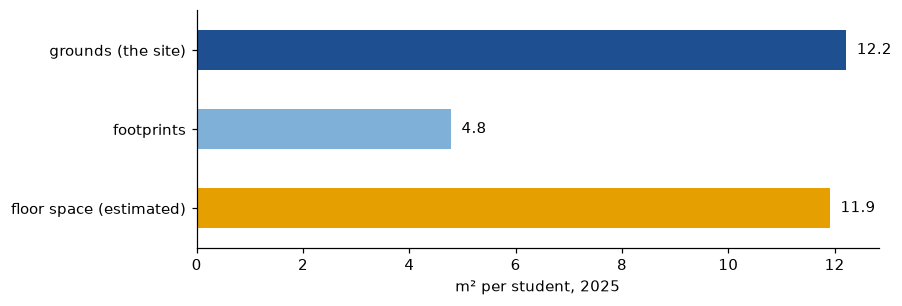

grounds (the site)         12.2
footprints                  4.8
floor space (estimated)    11.9
dtype: float64

In [7]:
y = 2025
per = pd.Series({'grounds (the site)': site_m2, 'footprints': fp_total, 'floor space (estimated)': floor_total}) / fte[y]
ax = per.plot.barh(color=[INK, '#7fb0d8', '#E69F00'], figsize=(8, 2.8)); ax.invert_yaxis()
ax.set_xlabel(f'm² per student, {y}')
for i, v in enumerate(per): ax.text(v + .2, i, f'{v:.1f}', va='center')
plt.show(); per.round(1)

## When the buildings appeared

Each building's footprint on the council's snapshots (blank: not on that layer). The six single-storey buildings of
about 200 m² are on the 2023 footprints (captured January 2022) and not on the 2020 ones.

year
2014     3
2015     4
2018     7
2020     7
2023    13
Name: buildings shown, dtype: int64
New between the 2020 and 2023 footprints: 6 buildings, 1,195 m²; enrolment 1,662 in 2020, 1,983 in 2025


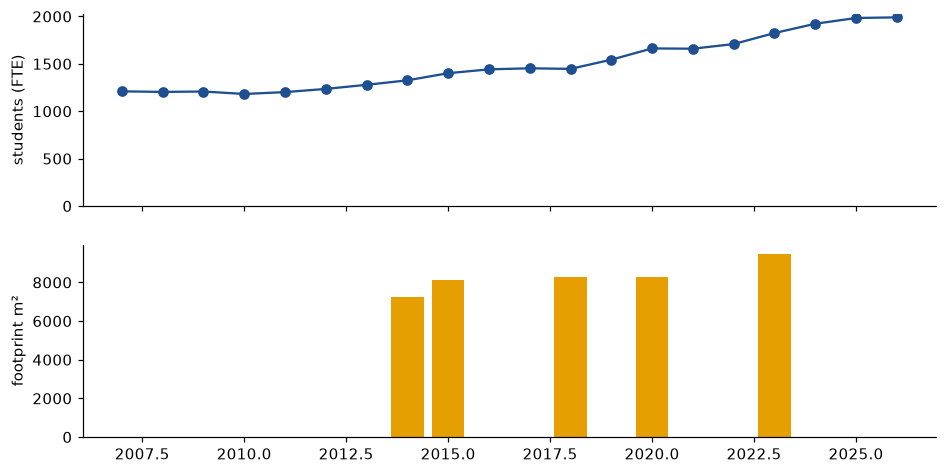

In [8]:
wide = fy.pivot(index='key', columns='year', values='footprint_m2')
print(wide.notna().sum().rename('buildings shown'))
new = wide[wide[2020].isna() & wide[2023].notna()]
print(f'New between the 2020 and 2023 footprints: {len(new)} buildings, {new[2023].sum():,.0f} m²; enrolment {fte[2020]:,.0f} in 2020, {fte[2025]:,.0f} in 2025')
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(fte.index, fte.values, color=INK, marker='o'); ax[0].set_ylabel('students (FTE)'); ax[0].set_ylim(0, None)
ax[1].bar(wide.columns, wide.sum(), color='#E69F00'); ax[1].set_ylabel('footprint m²')
plt.show()

## Accessibility, where it is recorded

CLUE rates the accessibility of the buildings it records (0 not rated to 3 high). On this campus that is two of the
thirteen buildings; the rest have no record at all, which is itself the finding: a site-level record cannot say which
building a wheelchair user can get into.

In [9]:
b[['key', 'clue_building_name', 'clue_accessibility_rating', 'clue_accessibility_type']].astype(object).fillna('no CLUE record')

,key,clue_building_name,clue_accessibility_rating,clue_accessibility_type
0,B01,University High School,2.0,Moderate level of accessibility
1,B02,no CLUE record,no CLUE record,no CLUE record
2,B03,Building 405 Elizabeth Blackburn,3.0,High level of accessibility
3,B04,no CLUE record,no CLUE record,no CLUE record
4,B05,no CLUE record,no CLUE record,no CLUE record
5,B06,no CLUE record,no CLUE record,no CLUE record
6,B07,no CLUE record,no CLUE record,no CLUE record
7,B08,no CLUE record,no CLUE record,no CLUE record
8,B09,no CLUE record,no CLUE record,no CLUE record
9,B10,no CLUE record,no CLUE record,no CLUE record


## Sample data: where your own register goes

`data/sample/sample_facilities.csv` is sample data: the figures are invented for illustration, drawn at random from a
fixed seed, and are not about University High School or any real building. It shows the next step for a facilities team: join their own register
(condition, backlog, meters, rooms, asbestos register, essential safety measures) to the building keys. Nothing above
uses it.

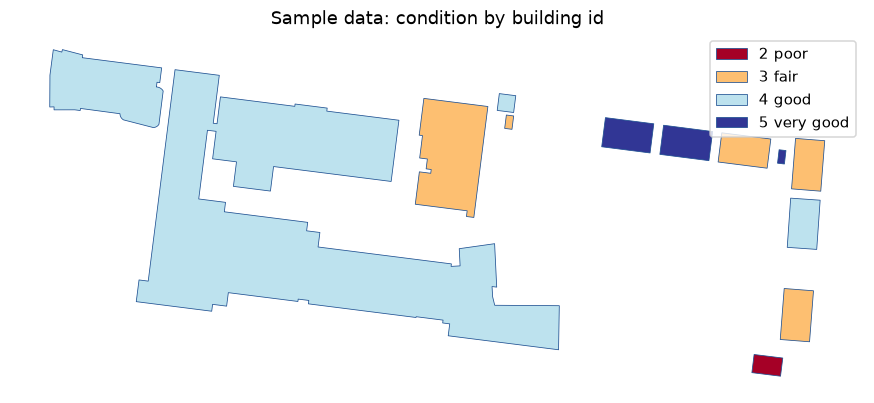

,key,sample_condition,sample_backlog_aud,sample_kwh_per_m2_floor,sample_teaching_spaces,sample_timetable_use_pct,sample_asbestos_register,sample_esm_status
0,B01,4 good,1083000,37.1,72,68.0,Register current,All items current
1,B02,3 fair,123000,47.8,8,95.0,Register review due,1 item open
2,B03,4 good,222000,76.2,10,89.0,Not expected (built after 2003),All items current
3,B04,3 fair,29000,74.1,2,65.0,Not expected (built after 2003),All items current
4,B05,3 fair,62000,93.6,2,76.0,Not expected (built after 2003),All items current
5,B06,4 good,21000,39.2,2,72.0,Not expected (built after 2003),All items current
6,B07,3 fair,83000,83.9,2,63.0,Not expected (built after 2003),1 item open
7,B08,5 very good,12000,35.9,2,84.0,Not expected (built after 2003),All items current
8,B09,5 very good,26000,36.4,2,55.0,Not expected (built after 2003),1 item open
9,B10,2 poor,32000,48.6,0,NaN,Register current,All items current


In [10]:
sample = pd.read_csv(f'{DATA}/sample/sample_facilities.csv', comment='#')
assert (sample.data_status == 'Sample data, invented').all()
s = shapes[['key', 'geometry']].merge(sample, on='key')
s['sample_kwh_per_m2_floor'] = s.sample_electricity_kwh_yr / s.key.map(b.set_index('key').floor_m2_est)
ax = s.plot(column='sample_condition', categorical=True, legend=True, cmap='RdYlBu', figsize=(10, 5.5), edgecolor=INK, lw=.5)
ax.set_axis_off(); ax.set_title('Sample data: condition by building id')
plt.show()
s[['key', 'sample_condition', 'sample_backlog_aud', 'sample_kwh_per_m2_floor', 'sample_teaching_spaces', 'sample_timetable_use_pct', 'sample_asbestos_register', 'sample_esm_status']].round(1)